# 04 · The numbers to follow every month

A dashboard needs a few numbers that the business can read at a glance and that mean the same thing every month. Here we **define 5 metrics with an exact formula**, compute them **by month** and **by group** with code, point out the unusual months, and try a simple forecast.

These are *monitoring* numbers, so they use all 12 months of 2023. (The models in notebook 06 never see the October-December flights until their final test.)

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from src import common, viz

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

common.require_processed("flights_clean.parquet", "destination_groups.parquet")
viz.apply_style()
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 120)

## 1. The 5 metrics
"Left" means the flight departed (it has a departure time). "Scheduled" means every flight in the table, including cancelled ones.

| # | Metric | Exact formula | Why the business cares | Up is |
|---|---|---|---|---|
| 1 | **On-time rate** | flights that left at most 15 minutes late / flights that left | The share of clients whose flight left on time. A flight that leaves early counts as on time. | good |
| 2 | **Average and median departure delay** | mean and median of `dep_delay` (minutes, negative = early) over flights that left | The typical wait. The median shows the usual flight, the average shows the pain of the few very late ones. | bad |
| 3 | **Cancellation rate** | scheduled flights with no departure time / scheduled flights | A cancelled flight is the worst outcome for a client: it needs rebooking. | bad |
| 4 | **Share more than 1 hour late** | flights that left more than 60 minutes late / flights that left | Long delays are the ones that break connections and trigger complaints. | bad |
| 5 | **Late-or-cancelled rate** | (flights that left more than 15 minutes late + cancelled flights) / scheduled flights | The one number the agency wants to keep low. It is also what our first prediction predicts. | bad |

In [2]:
DEFINITIONS = [
    ("on_time_rate", "flights that left at most 15 minutes late / flights that left", "Share of clients whose flight left on time. A flight that leaves early counts as on time.", "good"),
    ("avg_and_median_dep_delay", "mean and median of dep_delay (minutes, negative = early) over flights that left", "The typical wait: the median shows the usual flight, the average shows the pain of the few very late ones.", "bad"),
    ("cancellation_rate", "scheduled flights with no departure time / scheduled flights", "A cancelled flight is the worst outcome for a client: it needs rebooking.", "bad"),
    ("share_over_60", "flights that left more than 60 minutes late / flights that left", "Long delays break connections and trigger complaints.", "bad"),
    ("late_or_cancelled_rate", "(flights that left more than 15 minutes late + cancelled flights) / scheduled flights", "The one number the agency wants to keep low; it is what the first prediction predicts.", "bad"),
]
common.REPORTS.mkdir(parents=True, exist_ok=True)
pd.DataFrame(DEFINITIONS, columns=["metric", "formula", "why", "up_is"]).to_csv(common.REPORTS / "04_metric_definitions.csv", index=False)

def metrics(df):
    left = df[df["dep_delay"].notna()]
    return pd.Series({
        "flights": len(df),
        "on_time_rate": (left["dep_delay"] <= common.LATE_MINUTES).mean(),
        "avg_dep_delay": left["dep_delay"].mean(),
        "median_dep_delay": left["dep_delay"].median(),
        "cancellation_rate": df["cancelled"].mean(),
        "share_over_60": (left["dep_delay"] > 60).mean(),
        "late_or_cancelled_rate": df["late_or_cancelled"].mean(),
    })

## 2. The monthly table
One row per month, made by code from the cleaned flights.

In [3]:
flights = pd.read_parquet(common.PROC / "flights_clean.parquet")
by_month = flights.groupby("month").apply(metrics, include_groups=False)
by_month["flights"] = by_month["flights"].astype(int)
by_month.round(4).reset_index().to_csv(common.REPORTS / "04_metrics_by_month.csv", index=False)
assert len(by_month) == 12 and by_month["flights"].sum() == common.FLIGHT_ROWS
show = by_month.copy()
for c in ["on_time_rate", "cancellation_rate", "share_over_60", "late_or_cancelled_rate"]:
    show[c] = (show[c] * 100).round(1)
show[["avg_dep_delay", "median_dep_delay"]] = show[["avg_dep_delay", "median_dep_delay"]].round(1)
print("rates in %, delays in minutes")
print(show.to_string())

rates in %, delays in minutes
       flights  on_time_rate  avg_dep_delay  median_dep_delay  cancellation_rate  share_over_60  late_or_cancelled_rate
month                                                                                                                  
1        36020          77.6           14.0              -2.0                1.4            8.6                    23.5
2        34761          79.9           11.0              -3.0                1.6            7.1                    21.4
3        39514          78.0           13.0              -2.0                1.5            8.3                    23.1
4        37476          76.0           17.7              -2.0                2.8           10.2                    26.1
5        38710          82.9            8.4              -3.0                0.4            5.5                    17.4
6        35921          71.0           24.4              -1.0                6.0           13.5                    33.3
7        3

## 3. Which months look unusual?
We flag a month when its late-or-cancelled rate is more than one standard deviation away from the average of the 12 months (a "z-score" beyond 1 or below -1). We also check whether the weather at the three airports could explain it: the share of flights that ran in rain, snow, low visibility or strong gusts.

In [4]:
weather = pd.read_parquet(common.PROC / "weather_clean.parquet")
x = flights.merge(weather, on=["origin", "time_hour"], how="left")
assert len(x) == len(flights)
x["bad_weather"] = (x["precip"] > 0) | (x["visib"] < 3) | (x["wind_gust"] >= 25)
by_month["bad_weather_share"] = x.groupby("month")["bad_weather"].mean()
rate = by_month["late_or_cancelled_rate"]
by_month["z"] = (rate - rate.mean()) / rate.std()
unusual = by_month[by_month["z"].abs() > 1]
print(by_month[["late_or_cancelled_rate", "cancellation_rate", "avg_dep_delay", "bad_weather_share", "z"]].round(3).to_string())
print("\nunusual months:", unusual.index.tolist())

       late_or_cancelled_rate  cancellation_rate  avg_dep_delay  bad_weather_share      z
month                                                                                    
1                       0.235              0.014         14.023              0.251  0.081
2                       0.214              0.016         11.015              0.205 -0.189
3                       0.231              0.015         13.028              0.256  0.029
4                       0.261              0.028         17.683              0.189  0.409
5                       0.174              0.004          8.387              0.066 -0.705
6                       0.333              0.060         24.387              0.106  1.339
7                       0.391              0.087         30.463              0.089  2.076
8                       0.222              0.017         13.547              0.115 -0.086
9                       0.261              0.050         17.309              0.237  0.417
10        

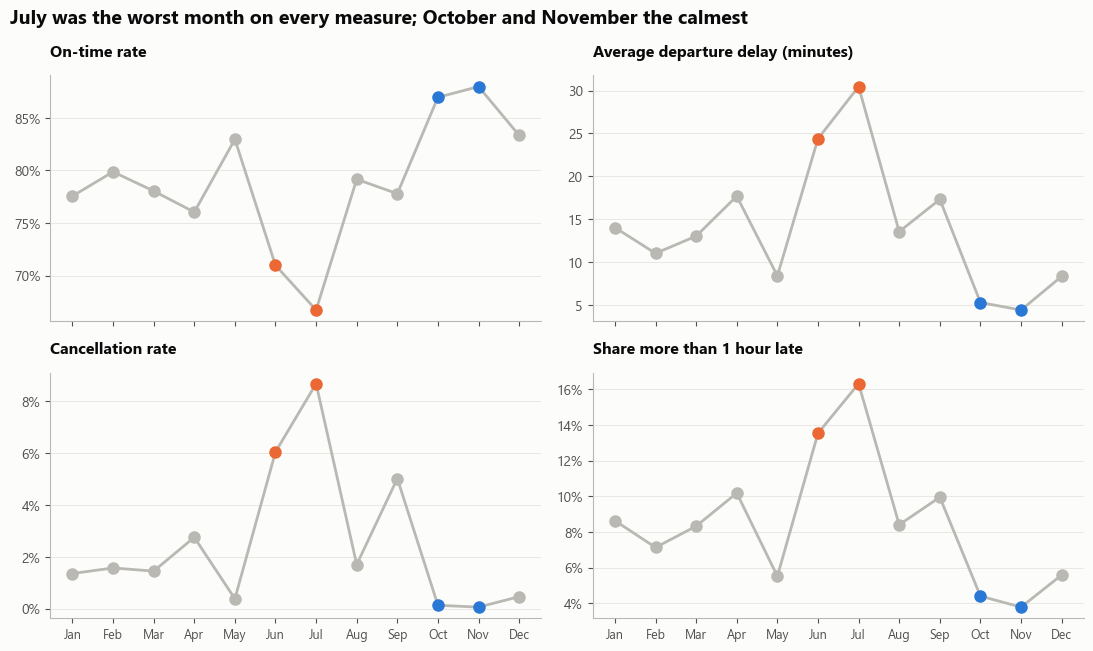

In [5]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
panels = [("on_time_rate", "On-time rate", True), ("avg_dep_delay", "Average departure delay (minutes)", False),
          ("cancellation_rate", "Cancellation rate", True), ("share_over_60", "Share more than 1 hour late", True)]
bad_months, calm_months = [m for m in unusual.index if unusual.loc[m, "z"] > 0], [m for m in unusual.index if unusual.loc[m, "z"] < 0]
fig, axes = plt.subplots(2, 2, figsize=(11, 6.6), sharex=True)
for ax, (col, title, is_pct) in zip(axes.flat, panels):
    ax.plot(range(1, 13), by_month[col], color=viz.GREY, linewidth=2)
    for m in range(1, 13):
        c = viz.ORANGE if m in bad_months else viz.BLUE if m in calm_months else viz.GREY
        ax.plot(m, by_month.loc[m, col], marker="o", markersize=8, color=c, linestyle="none")
    if is_pct:
        ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_title(title, fontsize=11.5)
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(MONTHS, fontsize=9)
fig.suptitle("July was the worst month on every measure; October and November the calmest", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
chart_m = viz.save_figure(fig, "04_monthly_metrics.png")
plt.show()

**Reading the unusual months**
- **June and July (worst):** July is bad on every measure: the usual flight leaves a little late (median +1 minute instead of -2 or -3), the average delay is more than double a typical month, and 8.7% of flights are cancelled. The cancellations come in waves on a few days (see notebook 02: 26-27 June, 9 and 16 July). The weather at the three airports does **not** explain it: July and June had some of the *smallest* shares of flights in bad weather. So the cause is outside our data (storms elsewhere on the routes or air-traffic limits are likely, but that is a guess).
- **October and November (calmest):** almost no cancellations (0.1%) and average delays of 4-5 minutes. The weather at the airports does not separate calm months from stormy ones: November had few flights in bad weather, but October an ordinary share. One year of data cannot tell whether this is a normal autumn pattern.
- **May** is also quiet (0.4% cancelled), but not far enough from the average to be flagged.

## 4. The same metrics for each group
By **airline**, by **origin airport**, and by the **destination groups** from notebook 03 (full year, all flights).

In [6]:
groups = pd.read_parquet(common.PROC / "destination_groups.parquet")
df = flights.merge(groups[["dest", "group_name"]], on="dest", how="left")
assert len(df) == len(flights) and df["group_name"].notna().all()
airline_names = (pd.read_csv(common.RAW / "airlines.csv").set_index("carrier")["name"].str.replace(r"\s+(Inc\.|Co\.|Corporation)$", "", regex=True))
parts = []
for dimension, col in [("carrier", "carrier"), ("origin", "origin"), ("dest_group", "group_name")]:
    g = df.groupby(col).apply(metrics, include_groups=False).reset_index().rename(columns={col: "level"})
    g.insert(0, "dimension", dimension)
    g["level_name"] = g["level"].map(airline_names) if dimension == "carrier" else g["level"]
    parts.append(g)
by_group = pd.concat(parts, ignore_index=True)
by_group["flights"] = by_group["flights"].astype(int)
by_group.round(4).to_csv(common.REPORTS / "04_metrics_by_group.csv", index=False)
by_month_group = df.groupby(["group_name", "month"]).apply(metrics, include_groups=False).reset_index()
by_month_group.round(4).to_csv(common.REPORTS / "04_metrics_by_month_group.csv", index=False)
cols = ["level_name", "flights", "on_time_rate", "avg_dep_delay", "cancellation_rate", "late_or_cancelled_rate"]
print(by_group[by_group["dimension"] != "carrier"][["dimension"] + cols].round(3).to_string(index=False))
print("\nairlines, from most to least often late or cancelled (a few rows):")
print(by_group[by_group["dimension"] == "carrier"].sort_values("late_or_cancelled_rate", ascending=False)[cols].head(5).round(3).to_string(index=False))

 dimension                                   level_name  flights  on_time_rate  avg_dep_delay  cancellation_rate  late_or_cancelled_rate
    origin                                          EWR   138578         0.773         15.404              0.026                   0.248
    origin                                          JFK   133048         0.775         15.904              0.021                   0.242
    origin                                          LGA   163726         0.818         10.824              0.026                   0.203
dest_group                    Afternoon build-up routes   237094         0.760         17.363              0.019                   0.255
dest_group Rare destinations (too few flights to judge)      445         0.781         13.925              0.007                   0.225
dest_group                       Steady regional routes   195819         0.831          9.276              0.031                   0.195
dest_group                 Thin routes wi

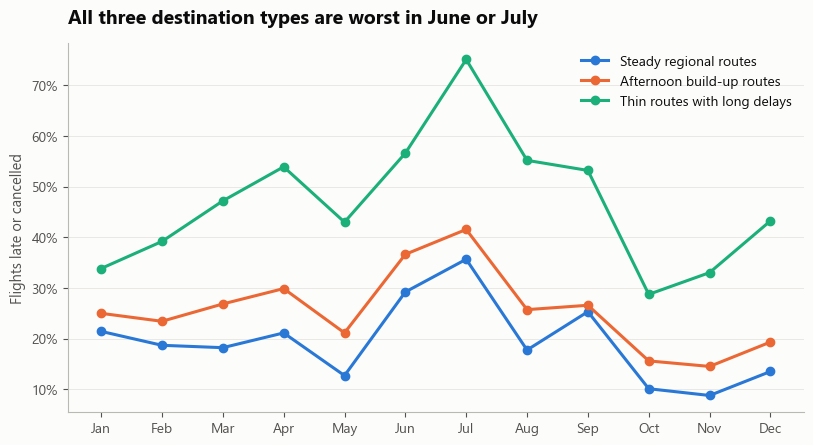

worst and best month for each group: {'Steady regional routes': (7, 11), 'Afternoon build-up routes': (7, 11), 'Thin routes with long delays': (7, 10)}


In [7]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
order = [(0, viz.BLUE), (1, viz.ORANGE), (2, viz.AQUA)]
names = groups.drop_duplicates("group_id").set_index("group_id")["group_name"]
peaks = {}
for gid, color in order:
    s = by_month_group[by_month_group["group_name"] == names[gid]].set_index("month")["late_or_cancelled_rate"]
    peaks[gid] = (s.idxmax(), s.idxmin())
    ax.plot(s.index, s.values, color=color, linewidth=2.2, marker="o", markersize=6, label=names[gid])
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xticks(range(1, 13)); ax.set_xticklabels(MONTHS)
ax.legend(loc="upper right")
same_peak = all(p[0] in (6, 7) for p in peaks.values())
ax.set_title("All three destination types are worst in June or July" if same_peak else "Destination types follow the seasons differently")
ax.set_ylabel("Flights late or cancelled")
chart_g = viz.save_figure(fig, "04_groups_by_month.png")
plt.show()
print("worst and best month for each group:", {names[g]: p for g, p in peaks.items()})

## 5. Bonus: forecast the last 3 months from the months before
We **forecast the late-or-cancelled rate for October, November and December** using only January to September. Two very simple methods, chosen before looking at the answer:
1. **Average of the last 3 known months** (July-September), our main method.
2. **Average of all 9 known months**, for comparison.

We then compare with what really happened. (A straight-line trend adds nothing with one year of data and is not tried.)

In [8]:
known = rate.loc[1:9]
actual = rate.loc[10:12]
methods = {"average of the last 3 known months": known.iloc[-3:].mean(), "average of all 9 known months": known.mean()}
rows = []
for name, value in methods.items():
    err = value - actual
    rows.append(dict(method=name, forecast=round(value, 4), mean_error_in_points=round(err.abs().mean() * 100, 1)))
print(pd.DataFrame(rows).to_string(index=False))
main = "average of the last 3 known months"
check = pd.DataFrame({"month": [10, 11, 12], "actual": actual.round(4).values, "forecast": round(methods[main], 4), "method": main})
check["error"] = (check["forecast"] - check["actual"]).round(4)
check.to_csv(common.REPORTS / "04_forecast_check.csv", index=False)
print(check.to_string(index=False))

                            method  forecast  mean_error_in_points
average of the last 3 known months    0.2913                  15.0
     average of all 9 known months    0.2579                  11.7
 month  actual  forecast                             method  error
    10  0.1317    0.2913 average of the last 3 known months 0.1596
    11  0.1209    0.2913 average of the last 3 known months 0.1704
    12  0.1706    0.2913 average of the last 3 known months 0.1207


**What we learn.** Both simple forecasts are too pessimistic: they predict about 26-29% late or cancelled, and the real autumn was 12-17%. The forecast had no way to know that autumn would be calmer, because we have **one year only** and so never saw a previous autumn. Two or more years would let a forecast learn the seasons. Until then the monthly table is for *monitoring* (spotting a bad month fast), not for planning.

## 6. Saved for later
`reports/04_metric_definitions.csv`, `04_metrics_by_month.csv`, `04_metrics_by_group.csv`, `04_metrics_by_month_group.csv` and `04_forecast_check.csv`. The decision cards (notebook 07) and the slides quote them.